In [1]:
from benchmark.evaluate import run_full_benchmark, score_matrix
from benchmark import plots
import pandas as pd

In [2]:
run_full_benchmark()

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  Loaded PPO ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/ppo/best_model.zip
  Loaded SAC ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/sac/best_model.zip
  Loaded TD3 ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/td3/best_model.zip

Benchmarking 6 policies: ['PPO', 'SAC', 'TD3', 'FiPla', 'Constant(0.5)', 'Random']
  Evaluating PPO (30 seeds) …
  Evaluating SAC (30 seeds) …
  Evaluating TD3 (30 seeds) …
  Evaluating FiPla (30 seeds) …
  Evaluating Constant(0.5) (30 seeds) …
  Evaluating Random (30 seeds) …

Results saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/results/benchmark_results.csv


,policy,seed,step,t,reward,cum_reward,won,bid,payment,ctx,expected_reward,competing_bid
0,PPO,0,1,0.113466,0.000000,0.000000,False,0.467431,0.000000,1.000000,0.000000,0.494734
1,PPO,1,1,1.906084,0.000000,0.000000,False,0.091391,0.000000,1.000000,1.000000,0.256389
2,PPO,1,2,4.494624,-0.400601,-0.400601,True,1.337821,0.400601,0.636307,0.000000,0.400601
3,PPO,1,3,4.522700,1.000000,0.599399,False,0.000000,0.000000,0.636307,0.000000,0.481988
4,PPO,1,4,5.330860,0.000000,0.599399,False,0.276483,0.000000,0.636307,0.118006,1.871850
...,...,...,...,...,...,...,...,...,...,...,...,...
7237,Random,28,1,1.391148,0.000000,0.000000,False,0.044247,0.000000,1.000000,0.000000,1.505979
7238,Random,29,1,6.093511,-0.469946,-0.469946,True,0.647220,0.469946,0.766758,0.000000,0.469946
7239,Random,29,2,7.775860,1.000000,0.530054,False,0.977286,0.000000,0.766758,0.590626,19.737515
7240,Random,29,3,9.696741,-0.185619,0.344435,True,1.540815,0.185619,0.763720,0.000000,0.185619


In [3]:
df = pd.read_csv("results/benchmark_results.csv")
scores = score_matrix(df)

In [4]:
df[(df["policy"] == "SAC") & (df["seed"] == 2)]

,policy,seed,step,t,reward,cum_reward,won,bid,payment,ctx,expected_reward,competing_bid
1468,SAC,2,1,3.698165,0.000000,0.000000,False,0.777714,0.000000,0.0,-0.000000,0.790566
1469,SAC,2,2,3.792393,0.000000,0.000000,False,0.622607,0.000000,0.0,0.000000,2.814730
1470,SAC,2,3,5.308361,0.000000,0.000000,False,0.725117,0.000000,0.0,-0.000000,1.091900
1471,SAC,2,4,6.623945,0.000000,0.000000,False,0.625697,0.000000,0.0,0.000000,0.755495
1472,SAC,2,5,6.646886,0.000000,0.000000,False,0.675449,0.000000,0.0,0.000000,0.836318
1473,SAC,2,6,7.142353,-0.216562,-0.216562,True,0.664474,0.216562,1.0,0.000000,0.216562
1474,SAC,2,7,9.726873,0.000000,-0.216562,False,0.590940,0.000000,1.0,0.254506,0.991084
1475,SAC,2,8,11.254242,-0.285308,-0.501870,True,0.684701,0.285308,2.0,0.000000,0.285308
1476,SAC,2,9,12.238148,0.000000,-0.501870,False,0.343219,0.000000,2.0,0.000000,0.501717
1477,SAC,2,10,13.853490,1.000000,0.498130,False,0.269985,0.000000,2.0,0.000000,0.874478


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/aggregate_metrics.pdf


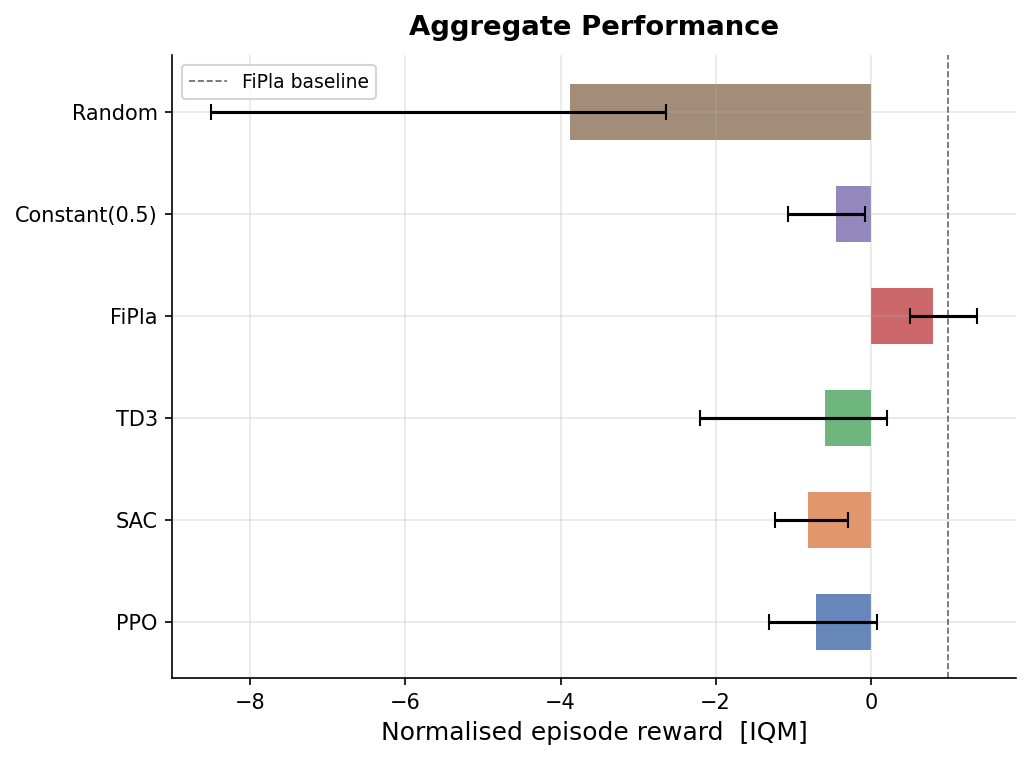

In [4]:
_ = plots.plot_aggregate_metrics(scores)

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/performance_profiles.pdf


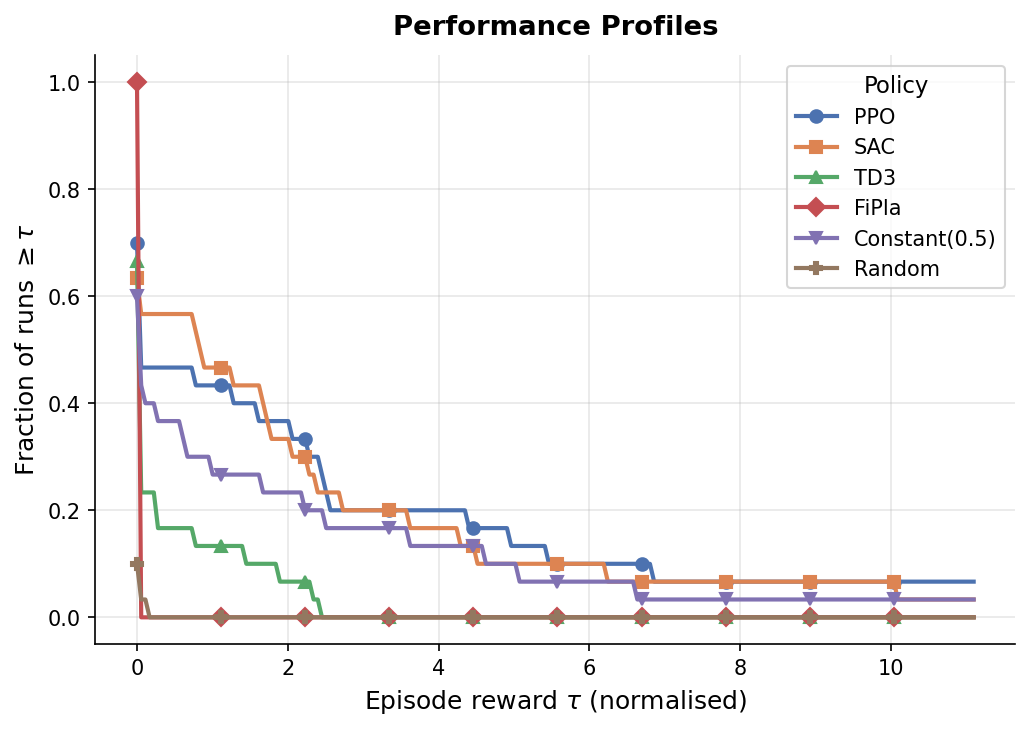

In [6]:
_ = plots.plot_performance_profiles(scores)

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/cumulative_reward.pdf


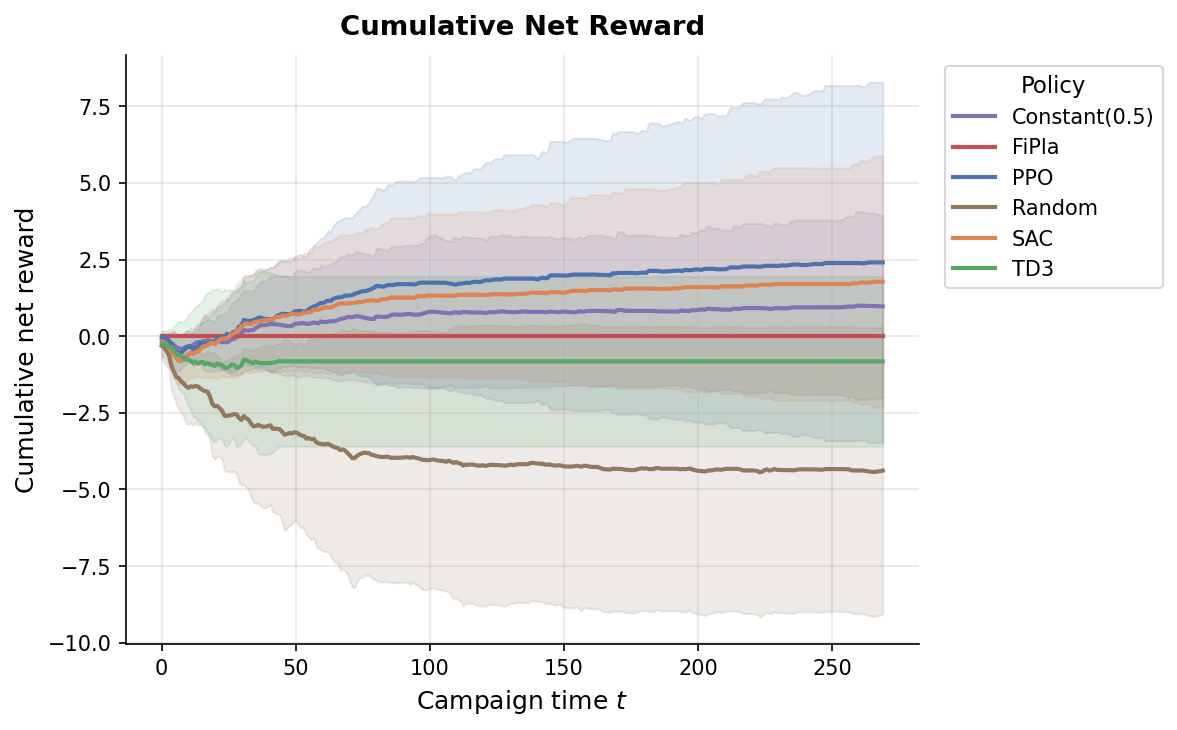

In [7]:
_ = plots.plot_cumulative_reward(df)

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:263: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/reward_distribution.pdf


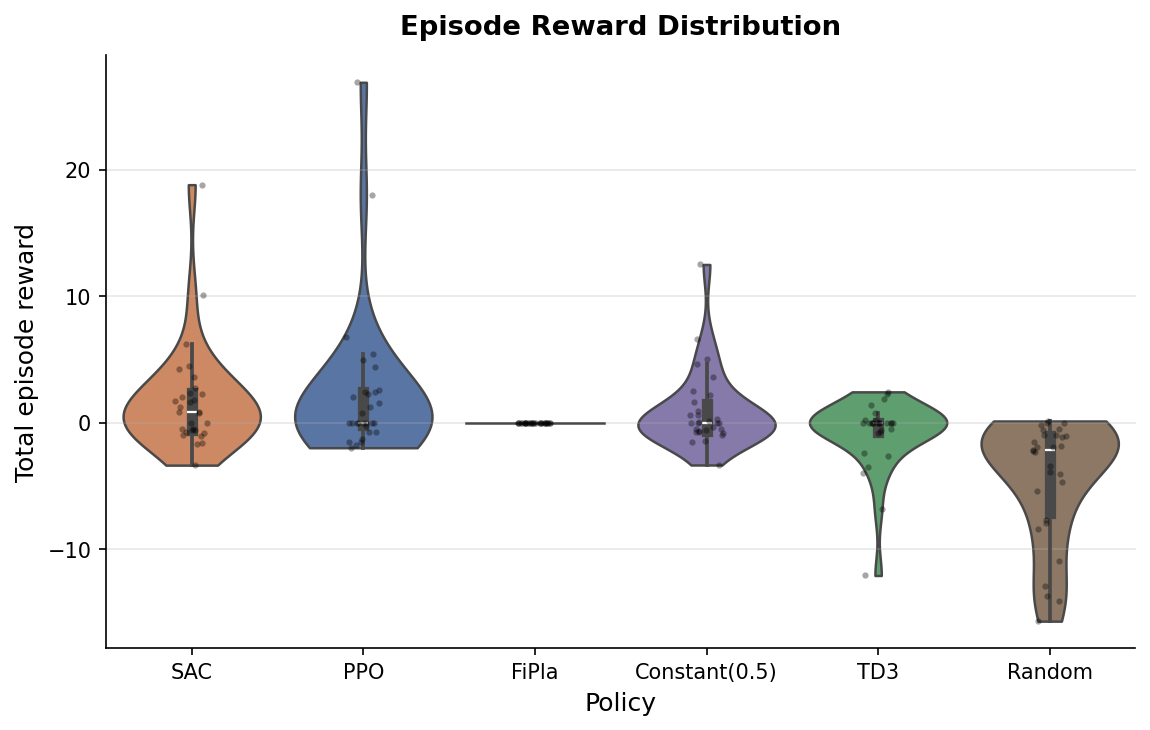

In [8]:
_ = plots.plot_reward_distribution(df)

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/training_curves.pdf


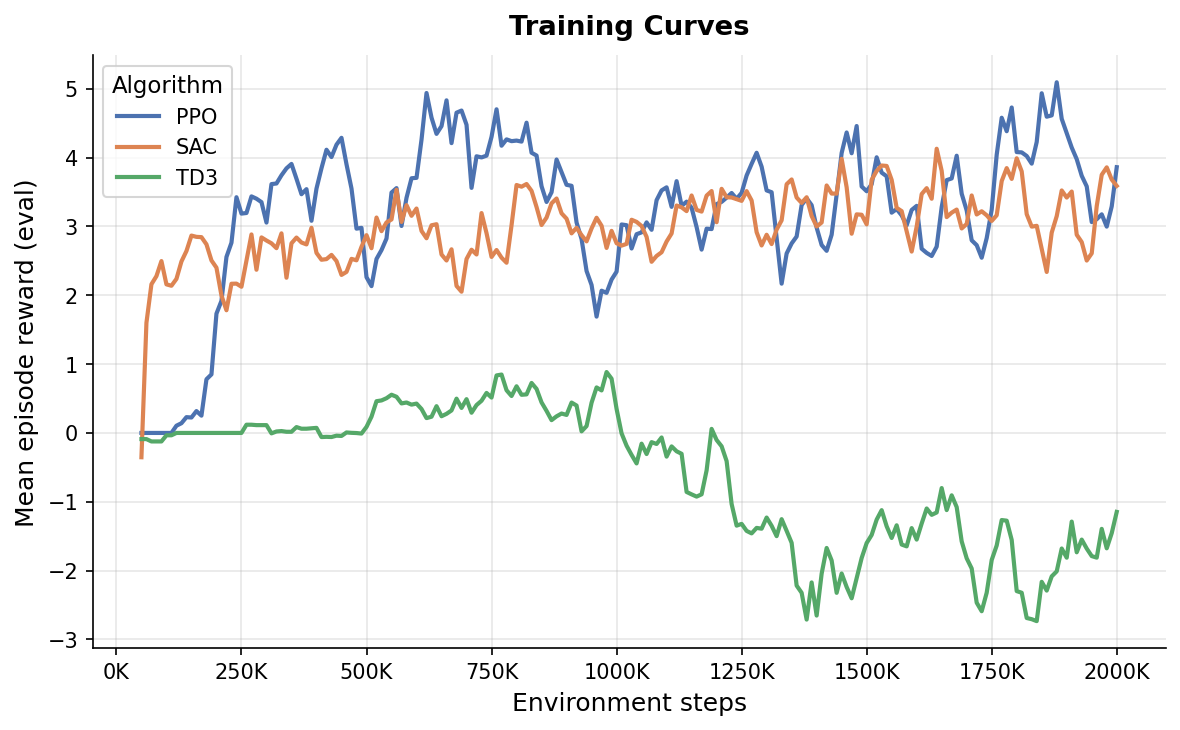

In [9]:
_ = plots.plot_training_curves()

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/context_dynamics.pdf


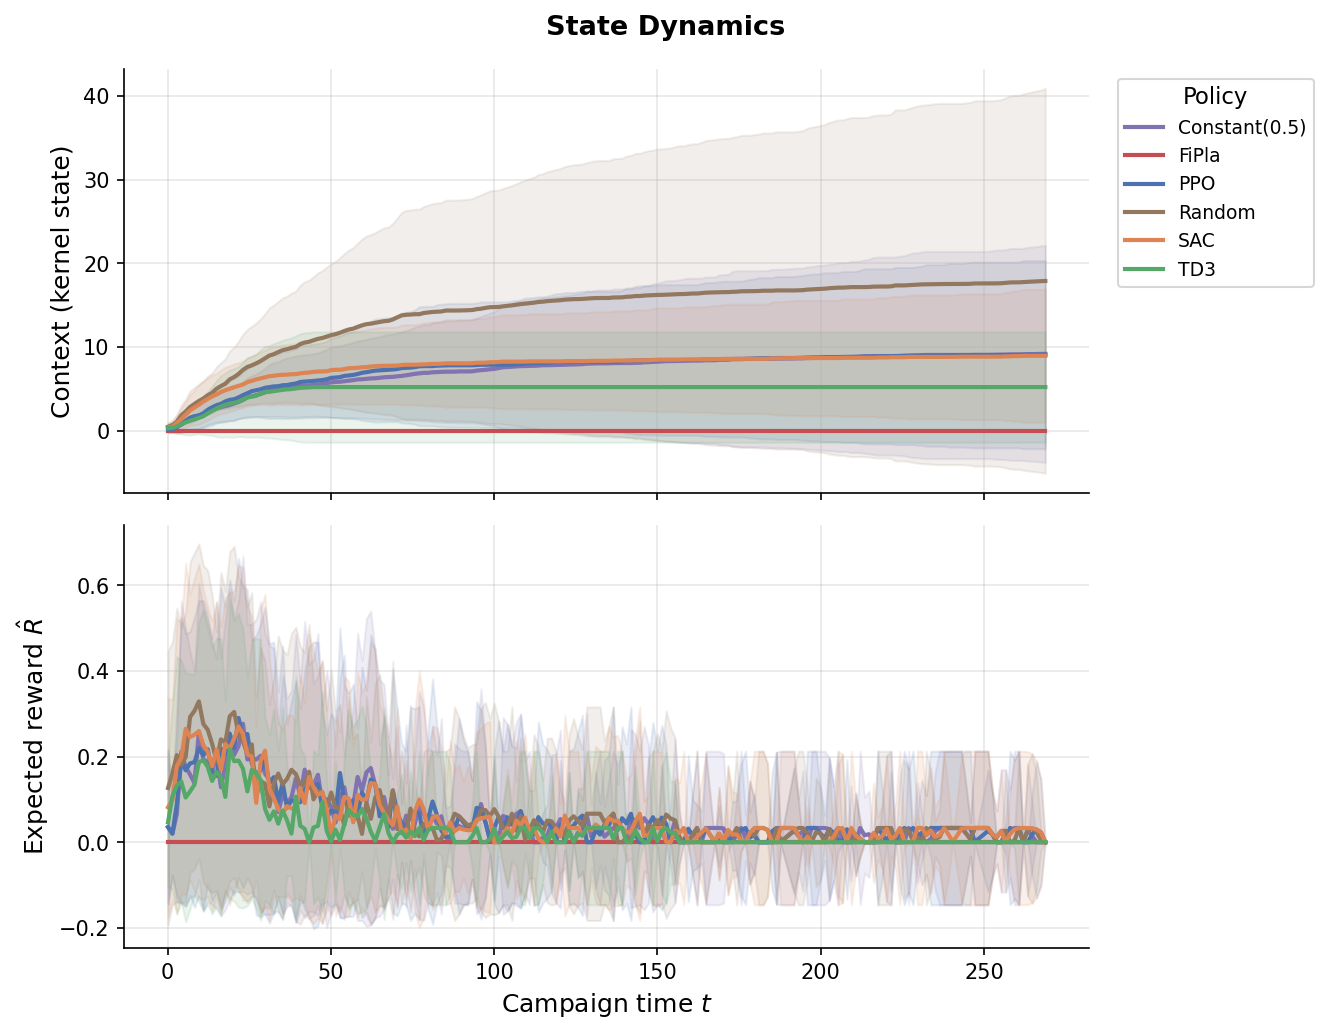

In [10]:
_ = plots.plot_context_dynamics(df)

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:443: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,
/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:443: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/bid_distributions.pdf


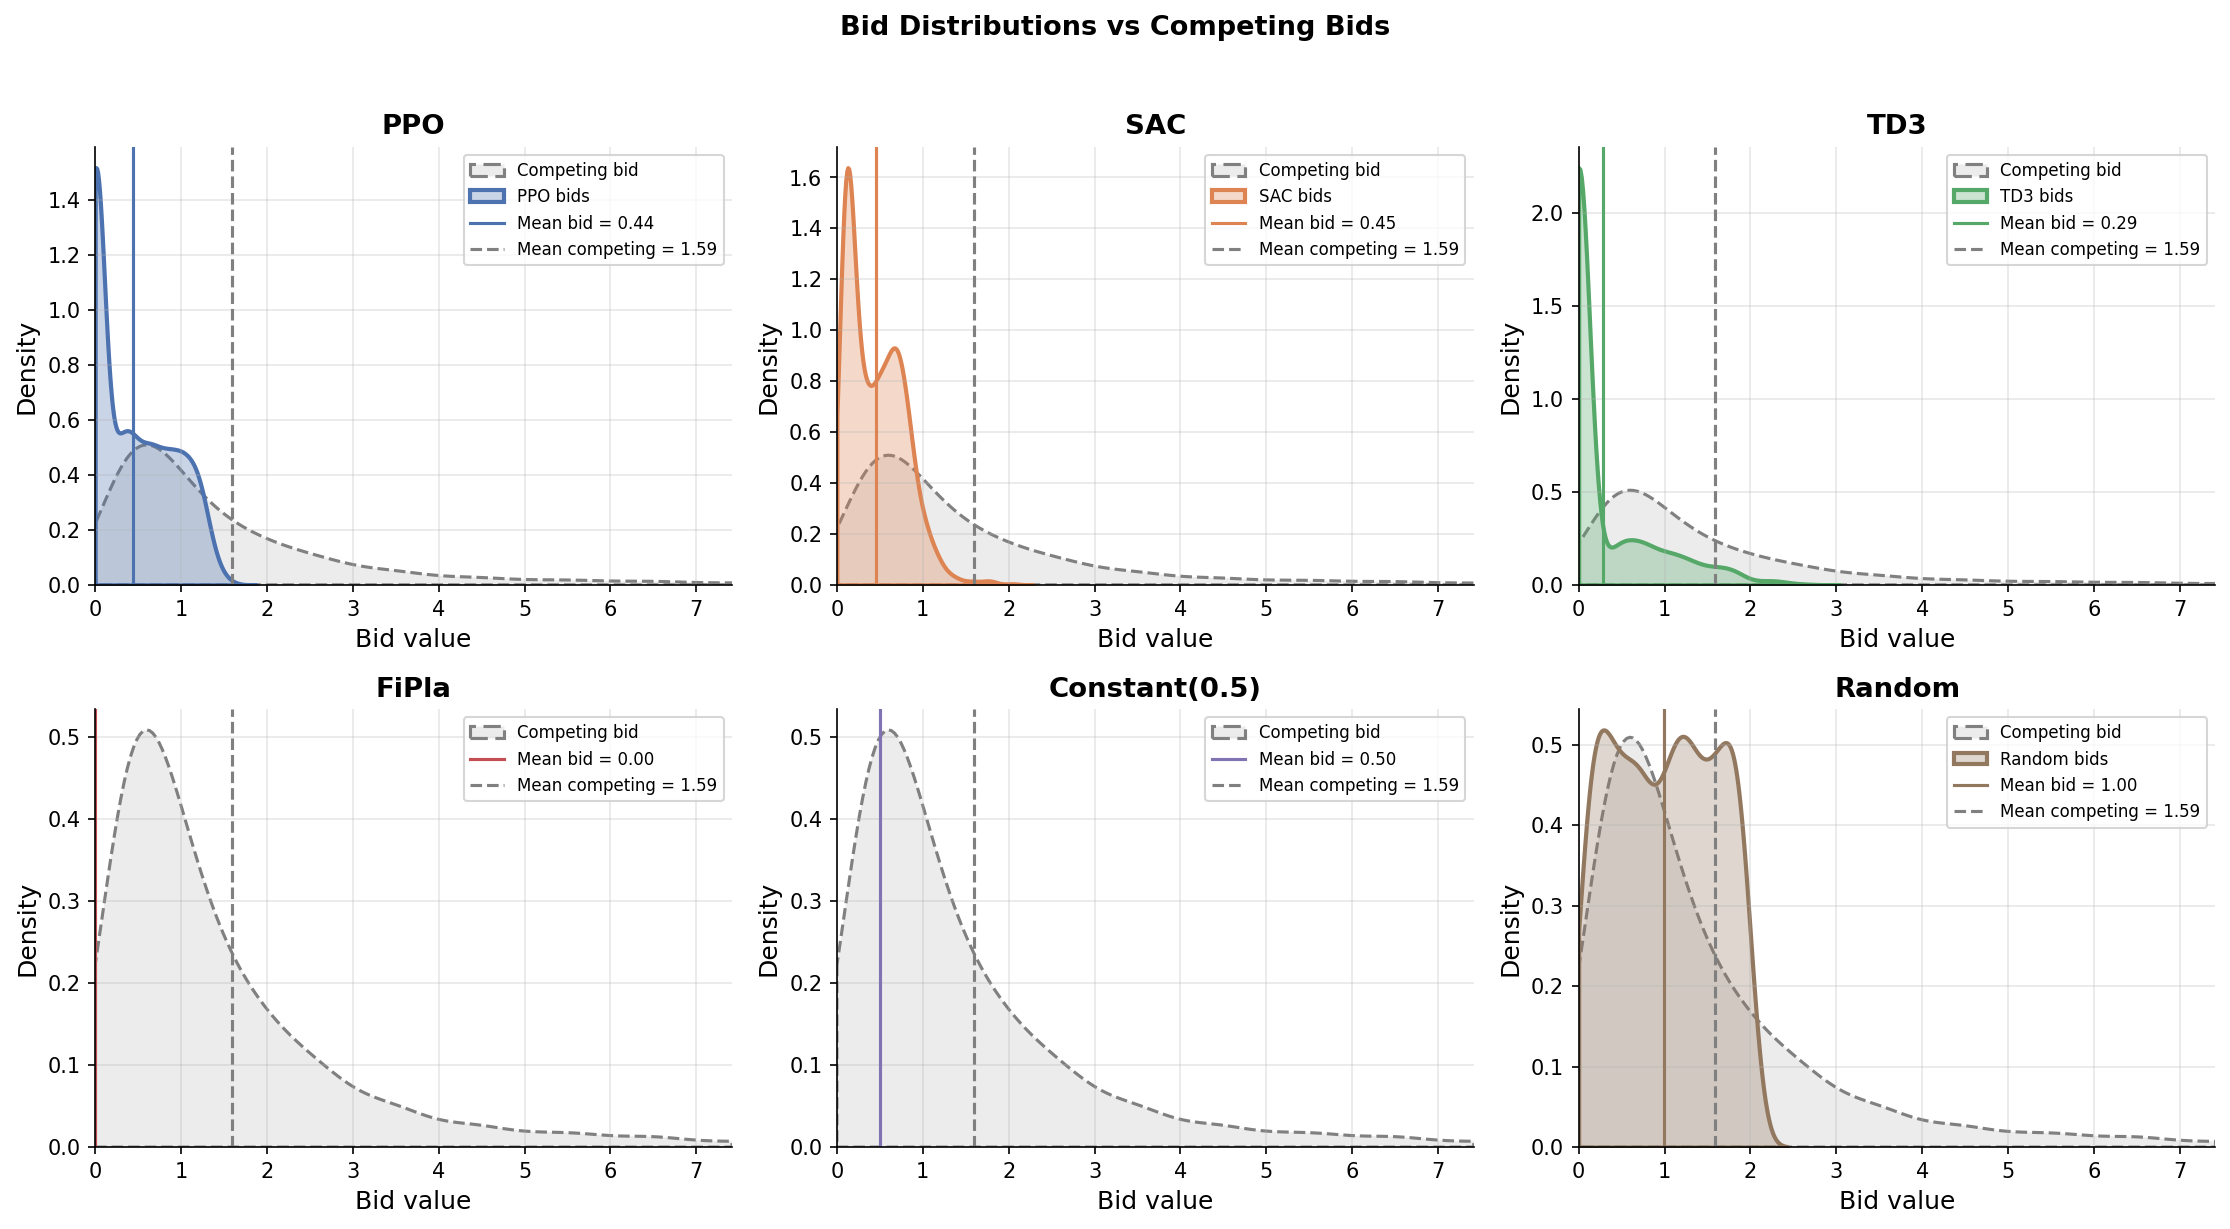

In [11]:
_ = plots.plot_bid_distributions(df)

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:418: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/win_rate.pdf


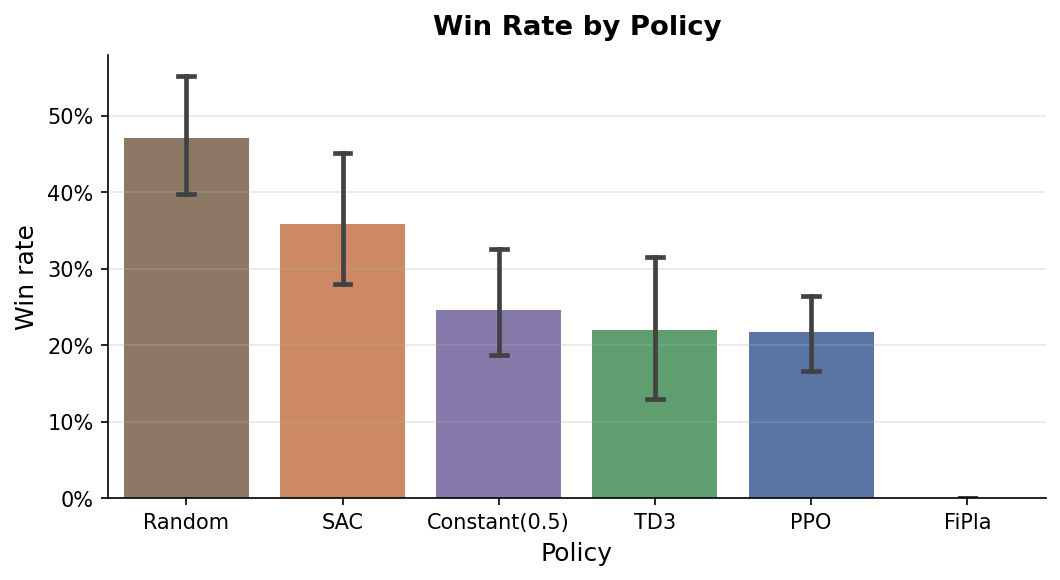

In [20]:
_ = plots.plot_win_rate(df)

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:528: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/full_benchmark.pdf


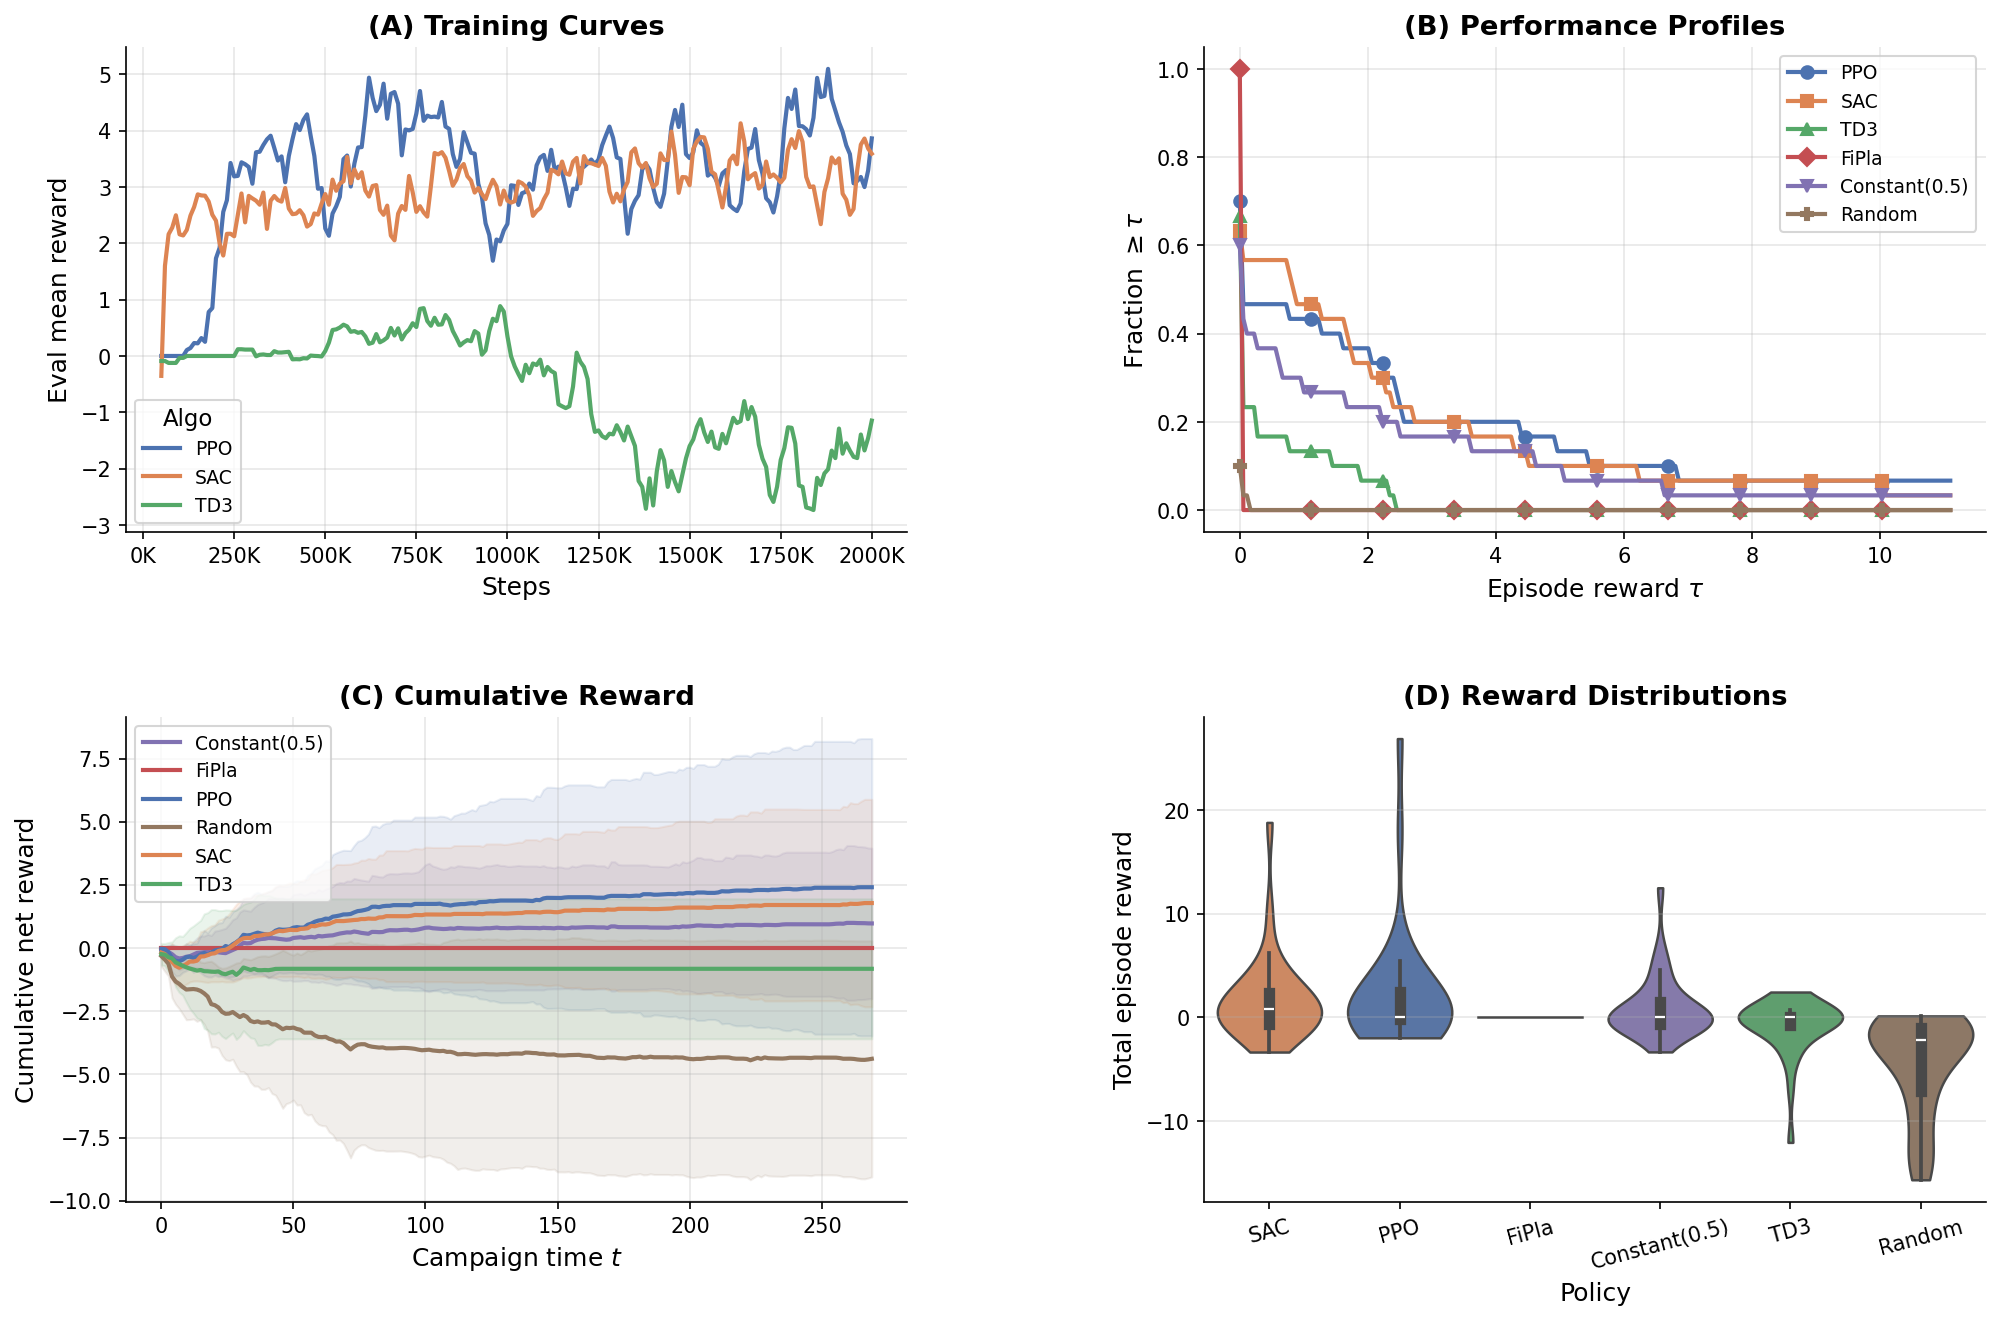

In [21]:
_ = plots.plot_full_benchmark(df, scores)

In [ ]:
s